# Unified UTHz and UOWC Modulation Simulation Framework

One end-to-end model comparing an **ultra-THz (UTHz)** link and an **underwater optical (UOWC)** link across several modulation formats.
Every figure and table below is driven by the same three building blocks, defined once:

1. **Configuration** (§1): every physical constant, noise level, sweep range and seed.
2. **Scheme registry and channel model** (§2–3): constellations, theoretical BER curves, path loss, link budget.
3. **Simulation engine** (§4): bit-level Monte-Carlo link (map → pulse-shape → noise → matched filter → decide).

| § | Content |
|---|---------|
| 1 | Configuration |
| 2 | Modulation scheme registry |
| 3 | Channel model and link budget |
| 4 | Simulation engine |
| 5 | Energy and transmission-time profile |
| 6 | Parameter sweeps (BER vs SNR / distance / data rate / received power) |
| 7 | Link characteristics (path loss, received power, Shannon limit) |
| 8 | Received constellations and eye diagrams at the link-budget operating point |
| 9 | Simulation vs theory validation |
| 10 | Consolidated summary table |

**Run order:** top to bottom (*Run all*). Sections 6–10 only read objects created in §1–5.

## 1. Configuration
Single source of truth. Change a value here and every downstream table and plot updates.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dataclasses import dataclass
from IPython.display import display
from scipy.signal import upfirdn
from scipy.special import erfc

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.4})

# --- Reproducibility --------------------------------------------------------
SEED = 42
rng = np.random.default_rng(SEED)

# --- Transmitter / signal ---------------------------------------------------
Pt                 = 100.0              # Transmit power (W)
R_s                = 1e9                # Symbol rate (1 Gsps)
sps                = 4                  # Samples per symbol for pulse shaping
rrc_rolloff        = 0.35               # Root-raised-cosine roll-off (shared TX/RX pulse filter)
rrc_span           = 8                  # RRC filter span in symbols (taps = span * sps + 1)
num_symbols        = 10_000             # Symbols per Monte-Carlo run (constellation plots)
num_symbols_ber    = 200_000            # Symbols per point in the BER validation (§9)
payload_size_bytes = 8 * 1024 * 1024    # 8 MB benchmark payload

# --- UTHz channel -----------------------------------------------------------
alpha_thz       = 12300      # Molecular extinction coefficient (1/m) at 0.25 THz
thz_wavelength  = 1e-3       # Wavelength used for free-space spreading (~0.3 THz band, 1 mm)
d_thz_ref       = 0.1e-3     # Reference distance (0.1 mm)
d_thz_demo      = 0.4e-3     # Operating point for constellation/eye plots (0.4 mm)
noise_floor_thz = 1e-3       # Noise power (W) used for the SNR = Pr / noise_floor link budget
noise_psd_thz   = 1e-10      # Noise PSD (W/Hz) used for the data-rate sweep

# --- UOWC channel -----------------------------------------------------------
alpha_opt        = 0.046     # Light extinction coefficient (1/m), clear water, 532 nm
uowc_divergence  = 1e-3      # Beam divergence (rad)
uowc_rx_radius   = 0.05      # Receiver aperture radius (m) -> 10 cm wide module
d_opt_ref        = 5.0       # Reference distance (m)
d_opt_demo       = 5.0       # Operating point for constellation/eye plots (m)
noise_floor_opt  = 0.5
noise_psd_opt    = 1e-9

# --- Sweep ranges -----------------------------------------------------------
snr_db_range     = np.linspace(0, 20, 200)            # BER vs SNR (Es/N0, dB)
p_rec_sweep_db   = np.linspace(-30, 20, 200)          # BER vs received power (dBW)
data_rates_sweep = np.logspace(7, 11, 200)            # BER vs data rate: 10 Mbps .. 100 Gbps
dist_thz_sweep   = np.linspace(0.01, 1.0, 200) * 1e-3 # 0.01 .. 1 mm
dist_opt_sweep   = np.linspace(1, 150, 200)           # 1 .. 150 m (BER only departs from zero beyond ~50 m)
ebn0_validation_db = np.arange(0, 15, 2)              # Eb/N0 grid for simulation vs theory

# --- Which scheme to feature in the eye diagrams ---------------------------
EYE_FOCUS = {"UTHz": "QPSK", "UOWC": "8-QAM"}

## 2. Modulation scheme registry
Each scheme carries its constellation (`points`, indexed by bit label and normalised to unit average power where applicable),
its bit labelling, and its theoretical BER as a function of **Eb/N0**.
QAM constellations are generated programmatically with Gray-coded axes, so the simulated BER is comparable with the Gray-coded theory.

*Note:* OOK, QPSK and 4-QAM have mathematically identical BER curves once SNR is converted to Eb/N0, so they overlap in the sweep plots (different line styles are used so each stays visible).
OFDM is represented by QPSK subcarriers with an 0.85 efficiency penalty, and 4-PPM by 4 amplitude slots; both are simulated as those proxies, so they are excluded from the §9 validation.

In [2]:
def gray_pam(n_bits):
    """PAM levels (..., -3, -1, +1, +3, ...) indexed by their Gray-coded bit label."""
    L = 2 ** n_bits
    positions = np.arange(L)
    levels = np.arange(-(L - 1), L, 2)
    levels_by_label = np.empty(L)
    levels_by_label[positions ^ (positions >> 1)] = levels
    return levels_by_label

def gray_qam(bits_i, bits_q):
    """Rectangular QAM with Gray-coded I/Q axes, label = (I bits | Q bits), unit average power."""
    i, q = gray_pam(bits_i), gray_pam(bits_q)
    pts = (i[:, None] + 1j * q[None, :]).ravel()
    return pts / np.sqrt(np.mean(np.abs(pts) ** 2))

def erfc_ber(a, b):
    """BER(Eb/N0) = a * erfc(sqrt(b * Eb/N0))."""
    return lambda ebn0: a * erfc(np.sqrt(b * ebn0))

def make_scheme(name, k, points, ber_func, sim_valid=True, note=""):
    points = np.asarray(points)
    assert len(points) == 2 ** k, f"{name}: needs 2^{k} constellation points"
    return {
        "name": name,
        "bits_per_symbol": k,
        "points": points,
        "is_one_dim": not np.iscomplexobj(points),
        "avg_power": float(np.mean(np.abs(points) ** 2)),
        "ber_func": ber_func,
        "sim_valid": sim_valid,   # False -> simulated only as a proxy constellation
        "note": note,
    }

QPSK_POINTS = gray_qam(1, 1)

MOD_SCHEMES_THZ = {
    "OOK":  make_scheme("OOK", 1, [0.0, 1.0], erfc_ber(0.5, 0.5)),
    "QPSK": make_scheme("QPSK", 2, QPSK_POINTS, erfc_ber(0.5, 1.0)),
    "OFDM": make_scheme("OFDM (QPSK-Subcarriers)", 2, QPSK_POINTS, erfc_ber(0.5, 0.85),
                        sim_valid=False, note="QPSK proxy"),
}

MOD_SCHEMES_OPT = {
    "4-QAM":  make_scheme("4-QAM", 2, gray_qam(1, 1), erfc_ber(0.5, 1.0)),
    "8-QAM":  make_scheme("8-QAM", 3, gray_qam(2, 1), erfc_ber(2 / 3, 0.6)),
    "16-QAM": make_scheme("16-QAM", 4, gray_qam(2, 2), erfc_ber(3 / 8, 0.8)),
    "4-PPM":  make_scheme("4-PPM", 2, [1.0, 2.0, 3.0, 4.0], erfc_ber(0.5, 2.0 / 4.0),
                          sim_valid=False, note="4-level amplitude proxy"),
    "QPSK":   make_scheme("QPSK", 2, QPSK_POINTS, erfc_ber(0.5, 1.0)),
}

LINE_STYLES = ["-", "--", "-.", ":", (0, (5, 1, 1, 1))]   # one per scheme so overlapping curves stay visible

## 3. Channel model and link budget
Total path loss = molecular/absorption loss `exp(α·d)` × geometric loss.
UTHz uses free-space spreading `(4πd/λ)²`; UOWC uses beam-to-aperture area ratio (1 when the beam is smaller than the receiver).
The link budget converts a distance into received power and SNR (`SNR = Pr / noise_floor`), and is the **only** place SNR is derived from geometry; sweeps, constellations and the summary all call it.

In [3]:
@dataclass
class Link:
    name: str
    channel: str
    schemes: dict
    alpha: float
    d_ref: float
    d_demo: float
    noise_floor: float
    noise_psd: float
    dist_sweep: np.ndarray
    dist_scale: float        # metres -> display unit
    dist_unit: str
    color: str

    def fmt(self, d):
        return f"{d * self.dist_scale:g} {self.dist_unit}"

LINKS = {
    "UTHz": Link("UTHz", "UTHz", MOD_SCHEMES_THZ, alpha_thz, d_thz_ref, d_thz_demo,
                 noise_floor_thz, noise_psd_thz, dist_thz_sweep, 1e3, "mm", "tab:orange"),
    "UOWC": Link("UOWC", "UOWC", MOD_SCHEMES_OPT, alpha_opt, d_opt_ref, d_opt_demo,
                 noise_floor_opt, noise_psd_opt, dist_opt_sweep, 1.0, "m", "tab:blue"),
}

def iter_schemes():
    """Yield (link, scheme) for every configured domain/modulation pair."""
    for link in LINKS.values():
        for cfg in link.schemes.values():
            yield link, cfg

def path_loss(d, link):
    """Total (linear) path loss at distance d (m); vectorised."""
    d = np.asarray(d, dtype=float)
    L_abs = np.exp(link.alpha * d)
    if link.channel == "UTHz":
        L_geo = (4 * np.pi * d / thz_wavelength) ** 2
    else:
        A_rx = np.pi * uowc_rx_radius ** 2
        A_beam = np.pi * (uowc_divergence * d / 2) ** 2
        L_geo = np.maximum(A_beam / A_rx, 1.0)
    return L_abs * L_geo

def link_budget(link, d):
    """Path loss, received power and SNR at distance d (scalar or array)."""
    L = path_loss(d, link)
    pr = Pt / L
    snr = pr / link.noise_floor
    return {"path_loss_db": 10 * np.log10(L), "pr_w": pr, "pr_dbw": 10 * np.log10(pr),
            "snr": snr, "snr_db": 10 * np.log10(snr)}

budget_rows = []
for link in LINKS.values():
    for label, d in (("reference", link.d_ref), ("demo", link.d_demo)):
        b = link_budget(link, d)
        budget_rows.append({"Domain": link.name, "Point": label, "Distance": link.fmt(d),
                            "Path loss (dB)": b["path_loss_db"], "Pr (dBW)": b["pr_dbw"],
                            "SNR (dB)": b["snr_db"]})
df_budget = pd.DataFrame(budget_rows)
display(df_budget.round(2))

,Domain,Point,Distance,Path loss (dB),Pr (dBW),SNR (dB)
0,UTHz,reference,0.1 mm,7.33,12.67,42.67
1,UTHz,demo,0.4 mm,35.39,-15.39,14.61
2,UOWC,reference,5 m,1.00,19.00,22.01
3,UOWC,demo,5 m,1.00,19.00,22.01


## 4. Simulation engine
`simulate_link` runs the full chain for one scheme at a requested symbol-domain SNR (Es/N0):
bits → Gray-labelled symbols → zero-stuffed upsampling and pulse-shaping → AWGN → matched filter → sampling at the decision instants → minimum-distance decoding → BER.

TX and RX share one **root-raised-cosine** pulse, so the cascade is (nearly) free of inter-symbol interference.
It is normalised to unit energy, so the matched-filter output at the decision instant equals the transmitted symbol (gain 1) and the noise keeps variance `N0`.
Filter delay is compensated exactly (`rrc_span · sps` samples for TX + RX). The absolute received power cancels out of the decision statistic, so SNR is passed in directly; the link budget (§3) supplies it.

In [4]:
def rrc_pulse(beta, span, sps):
    """Unit-energy root-raised-cosine pulse, length span*sps + 1."""
    t = np.arange(-span * sps // 2, span * sps // 2 + 1) / sps          # time in symbol periods
    h = np.empty_like(t)
    for i, ti in enumerate(t):
        if ti == 0:
            h[i] = 1 - beta + 4 * beta / np.pi
        elif np.isclose(abs(4 * beta * ti), 1.0):
            h[i] = (beta / np.sqrt(2)) * ((1 + 2 / np.pi) * np.sin(np.pi / (4 * beta))
                                          + (1 - 2 / np.pi) * np.cos(np.pi / (4 * beta)))
        else:
            h[i] = (np.sin(np.pi * ti * (1 - beta)) + 4 * beta * ti * np.cos(np.pi * ti * (1 + beta)))                    / (np.pi * ti * (1 - (4 * beta * ti) ** 2))
    return h / np.linalg.norm(h)

PULSE = rrc_pulse(rrc_rolloff, rrc_span, sps)
DELAY = rrc_span * sps                    # TX + RX group delay (samples)

def simulate_link(scheme, snr_db, n_symbols=num_symbols, rng=rng):
    """Monte-Carlo link at symbol-domain SNR `snr_db`. Returns dict(rx_sym, rx_mf, ber, ...)."""
    k, pts = scheme["bits_per_symbol"], scheme["points"]

    # Bits -> labels -> symbols
    bits = rng.integers(0, 2, (n_symbols, k))
    labels = bits @ (1 << np.arange(k - 1, -1, -1))
    tx = upfirdn(PULSE, pts[labels], up=sps)

    # AWGN: N0 set from the average symbol power; N0/2 per real dimension
    N0 = scheme["avg_power"] / 10 ** (snr_db / 10)
    sigma = np.sqrt(N0 / 2)
    noise = sigma * rng.standard_normal(len(tx))
    if not scheme["is_one_dim"]:
        noise = noise + 1j * sigma * rng.standard_normal(len(tx))
    rx = tx + noise

    # Matched filter (full rate, kept for eye diagrams) and symbol-rate sampling
    rx_mf = upfirdn(PULSE, rx)
    rx_sym = rx_mf[DELAY : DELAY + n_symbols * sps : sps]

    # Minimum-distance decoder
    idx = np.abs(rx_sym[:, None] - pts[None, :]).argmin(axis=1)
    rx_bits = (idx[:, None] >> np.arange(k - 1, -1, -1)) & 1
    errors = int(np.count_nonzero(rx_bits != bits))
    return {"rx_sym": rx_sym, "rx_mf": rx_mf, "ber": errors / bits.size, "bit_errors": errors, "snr_db": snr_db}

## 5. Energy and transmission-time profile
Time and energy to move the 8 MB payload at `R_s · bits_per_symbol`, with transmit power `Pt` held constant.

In [5]:
payload_bits = payload_size_bytes * 8

energy_rows = []
for link, cfg in iter_schemes():
    rate = R_s * cfg["bits_per_symbol"]
    duration = payload_bits / rate
    energy_rows.append({
        "Domain": link.name,
        "Modulation": cfg["name"],
        "Bits/Symbol": cfg["bits_per_symbol"],
        "Data Rate (Gbps)": rate / 1e9,
        "Duration (ms)": duration * 1e3,
        "Energy Spent (J)": Pt * duration,
    })

df_energy = pd.DataFrame(energy_rows)
display(df_energy.round(3))

,Domain,Modulation,Bits/Symbol,Data Rate (Gbps),Duration (ms),Energy Spent (J)
0,UTHz,OOK,1,1.0,67.109,6.711
1,UTHz,QPSK,2,2.0,33.554,3.355
2,UTHz,OFDM (QPSK-Subcarriers),2,2.0,33.554,3.355
3,UOWC,4-QAM,2,2.0,33.554,3.355
4,UOWC,8-QAM,3,3.0,22.370,2.237
5,UOWC,16-QAM,4,4.0,16.777,1.678
6,UOWC,4-PPM,2,2.0,33.554,3.355
7,UOWC,QPSK,2,2.0,33.554,3.355


## 6. Parameter sweeps
All four sweeps use the same registry, link budget and noise settings from §1–3.
Each sweep is stored as `(x, SNR)` per link; `ber_func(SNR / bits_per_symbol)` then gives the theoretical BER of every scheme.

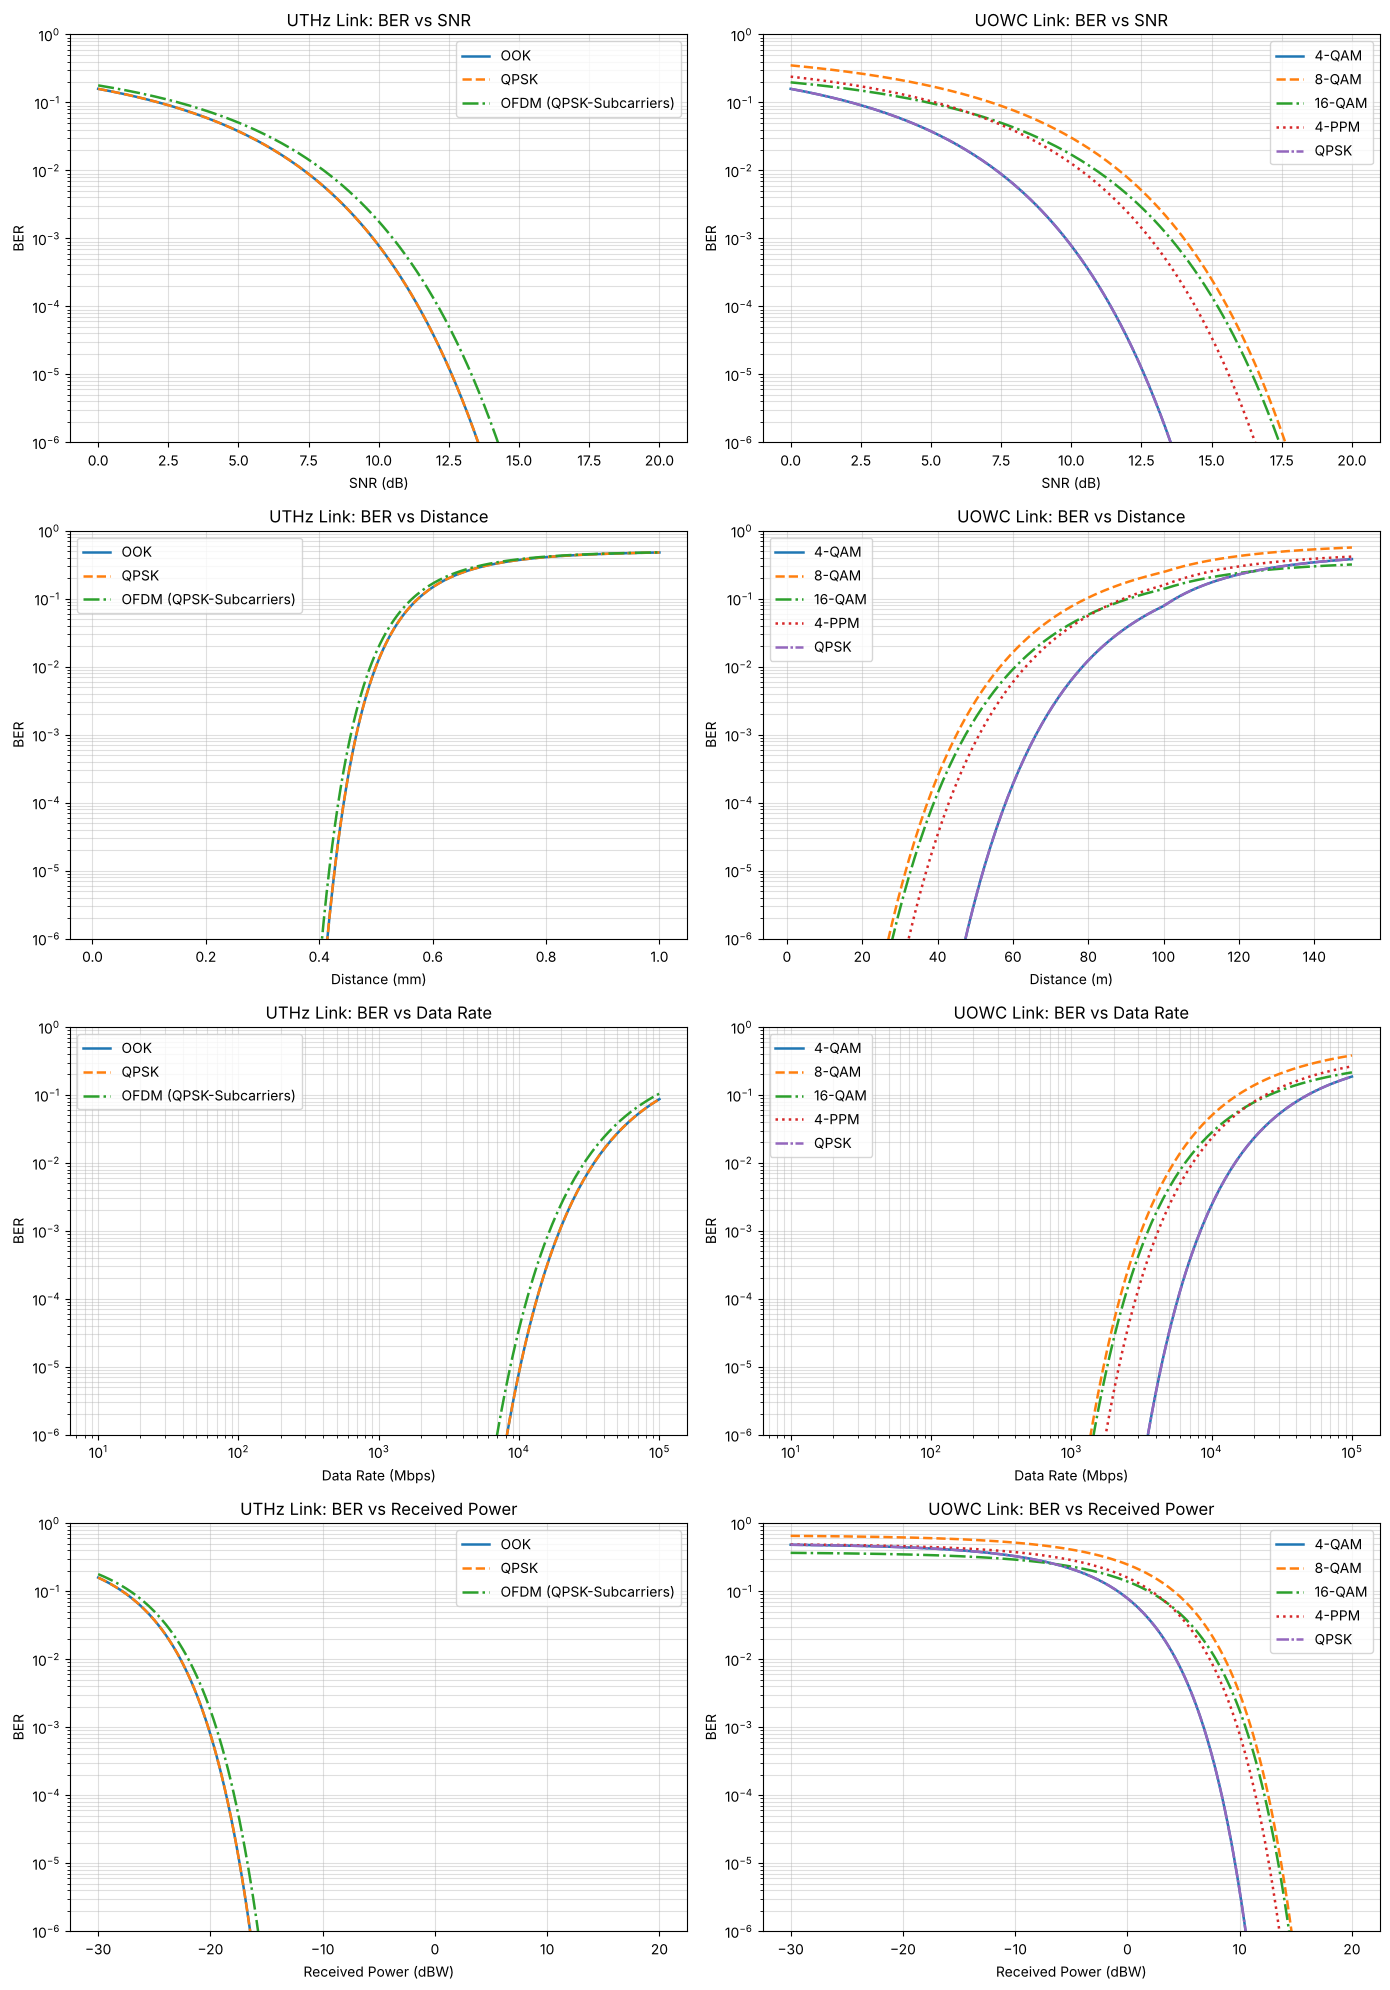

In [6]:
snr_lin_range = 10 ** (snr_db_range / 10)
p_rec_lin = 10 ** (p_rec_sweep_db / 10)

SWEEP_ORDER = ["SNR", "Distance", "Data Rate", "Received Power"]
SWEEPS = {}          # SWEEPS[link][sweep] = (x, snr_linear, xlabel, xscale)
for link in LINKS.values():
    b_dist = link_budget(link, link.dist_sweep)
    pr_ref = link_budget(link, link.d_ref)["pr_w"]
    SWEEPS[link.name] = {
        "SNR":            (snr_db_range, snr_lin_range, "SNR (dB)", "linear"),
        "Distance":       (link.dist_sweep * link.dist_scale, b_dist["snr"], f"Distance ({link.dist_unit})", "linear"),
        "Data Rate":      (data_rates_sweep / 1e6, pr_ref / (link.noise_psd * data_rates_sweep), "Data Rate (Mbps)", "log"),
        "Received Power": (p_rec_sweep_db, p_rec_lin / link.noise_floor, "Received Power (dBW)", "linear"),
    }

def plot_ber_curves(ax, link, sweep):
    x, snr, xlabel, xscale = SWEEPS[link.name][sweep]
    for style, cfg in zip(LINE_STYLES, link.schemes.values()):
        ax.plot(x, cfg["ber_func"](snr / cfg["bits_per_symbol"]), ls=style, lw=1.8, label=cfg["name"])
    ax.set(xscale=xscale, yscale="log", ylim=(1e-6, 1), xlabel=xlabel, ylabel="BER",
           title=f"{link.name} Link: BER vs {sweep}")
    ax.grid(True, which="both")
    ax.legend()

fig, axes = plt.subplots(len(SWEEP_ORDER), len(LINKS), figsize=(14, 5 * len(SWEEP_ORDER)))
for r, sweep in enumerate(SWEEP_ORDER):
    for c, link in enumerate(LINKS.values()):
        plot_ber_curves(axes[r, c], link, sweep)
plt.tight_layout()
plt.show()

## 7. Link characteristics
Path loss and received power over the *same* distance sweeps as §6 (received power in dBW is `10·log10(Pt) − path loss`, shown on the right axis),
plus the Shannon limit for bandwidth `B = R_s` over the §6 SNR range.

Note that the free-space UTHz model gives *negative* path loss below ~0.08 mm (near-field, where `(4πd/λ)² < 1`); this is a limitation of the formula, not of the plot.

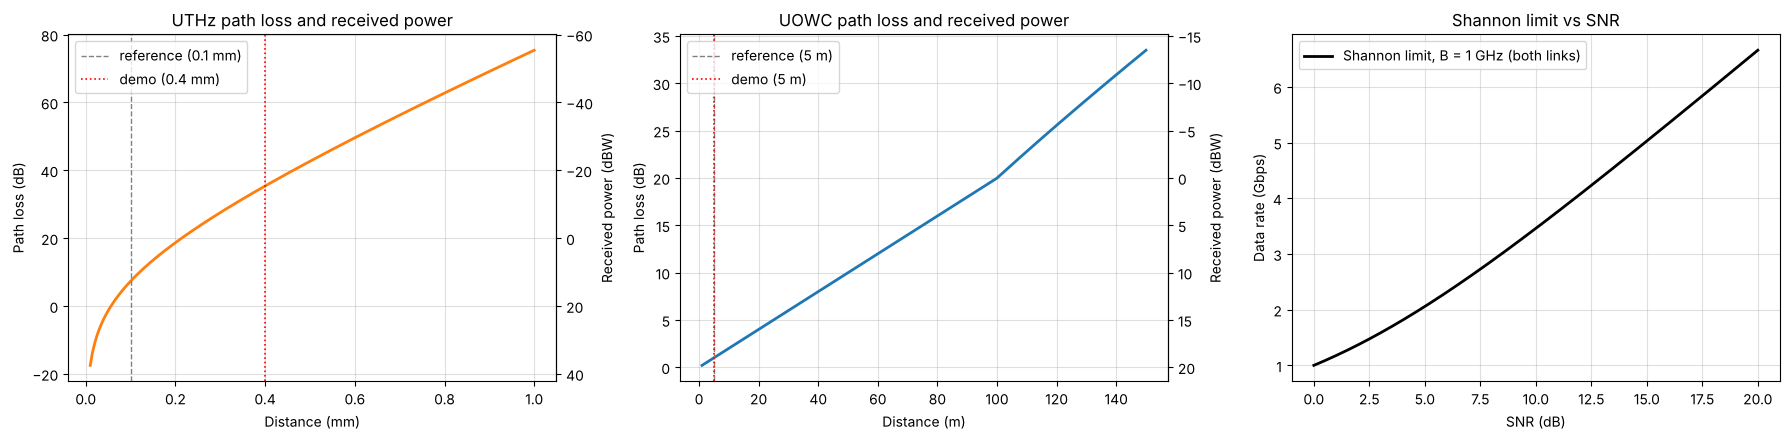

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

for ax, link in zip(axes[:2], LINKS.values()):
    b = link_budget(link, link.dist_sweep)
    x = link.dist_sweep * link.dist_scale
    ax.plot(x, b["path_loss_db"], color=link.color, lw=2)
    ax.axvline(link.d_ref * link.dist_scale, color="gray", ls="--", lw=1, label=f"reference ({link.fmt(link.d_ref)})")
    ax.axvline(link.d_demo * link.dist_scale, color="red", ls=":", lw=1.2, label=f"demo ({link.fmt(link.d_demo)})")
    ax.set(xlabel=f"Distance ({link.dist_unit})", ylabel="Path loss (dB)", title=f"{link.name} path loss and received power")
    sec = ax.secondary_yaxis("right", functions=(lambda pl: 10 * np.log10(Pt) - pl, lambda pr: 10 * np.log10(Pt) - pr))
    sec.set_ylabel("Received power (dBW)")
    ax.legend(loc="upper left")

capacity = R_s * np.log2(1 + snr_lin_range) / 1e9
axes[2].plot(snr_db_range, capacity, color="black", lw=2, label=f"Shannon limit, B = {R_s/1e9:g} GHz (both links)")
axes[2].set(xlabel="SNR (dB)", ylabel="Data rate (Gbps)", title="Shannon limit vs SNR")
axes[2].legend()

plt.tight_layout()
plt.show()

## 8. Received constellations and eye diagrams at the link-budget operating point
Each scheme is simulated at the SNR the link budget (§3) gives at the domain's **demo distance**
(`d_thz_demo`, `d_opt_demo` in §1). No SNR is hard-coded per plot. Results are kept in `demo_results` and reused by the summary table.

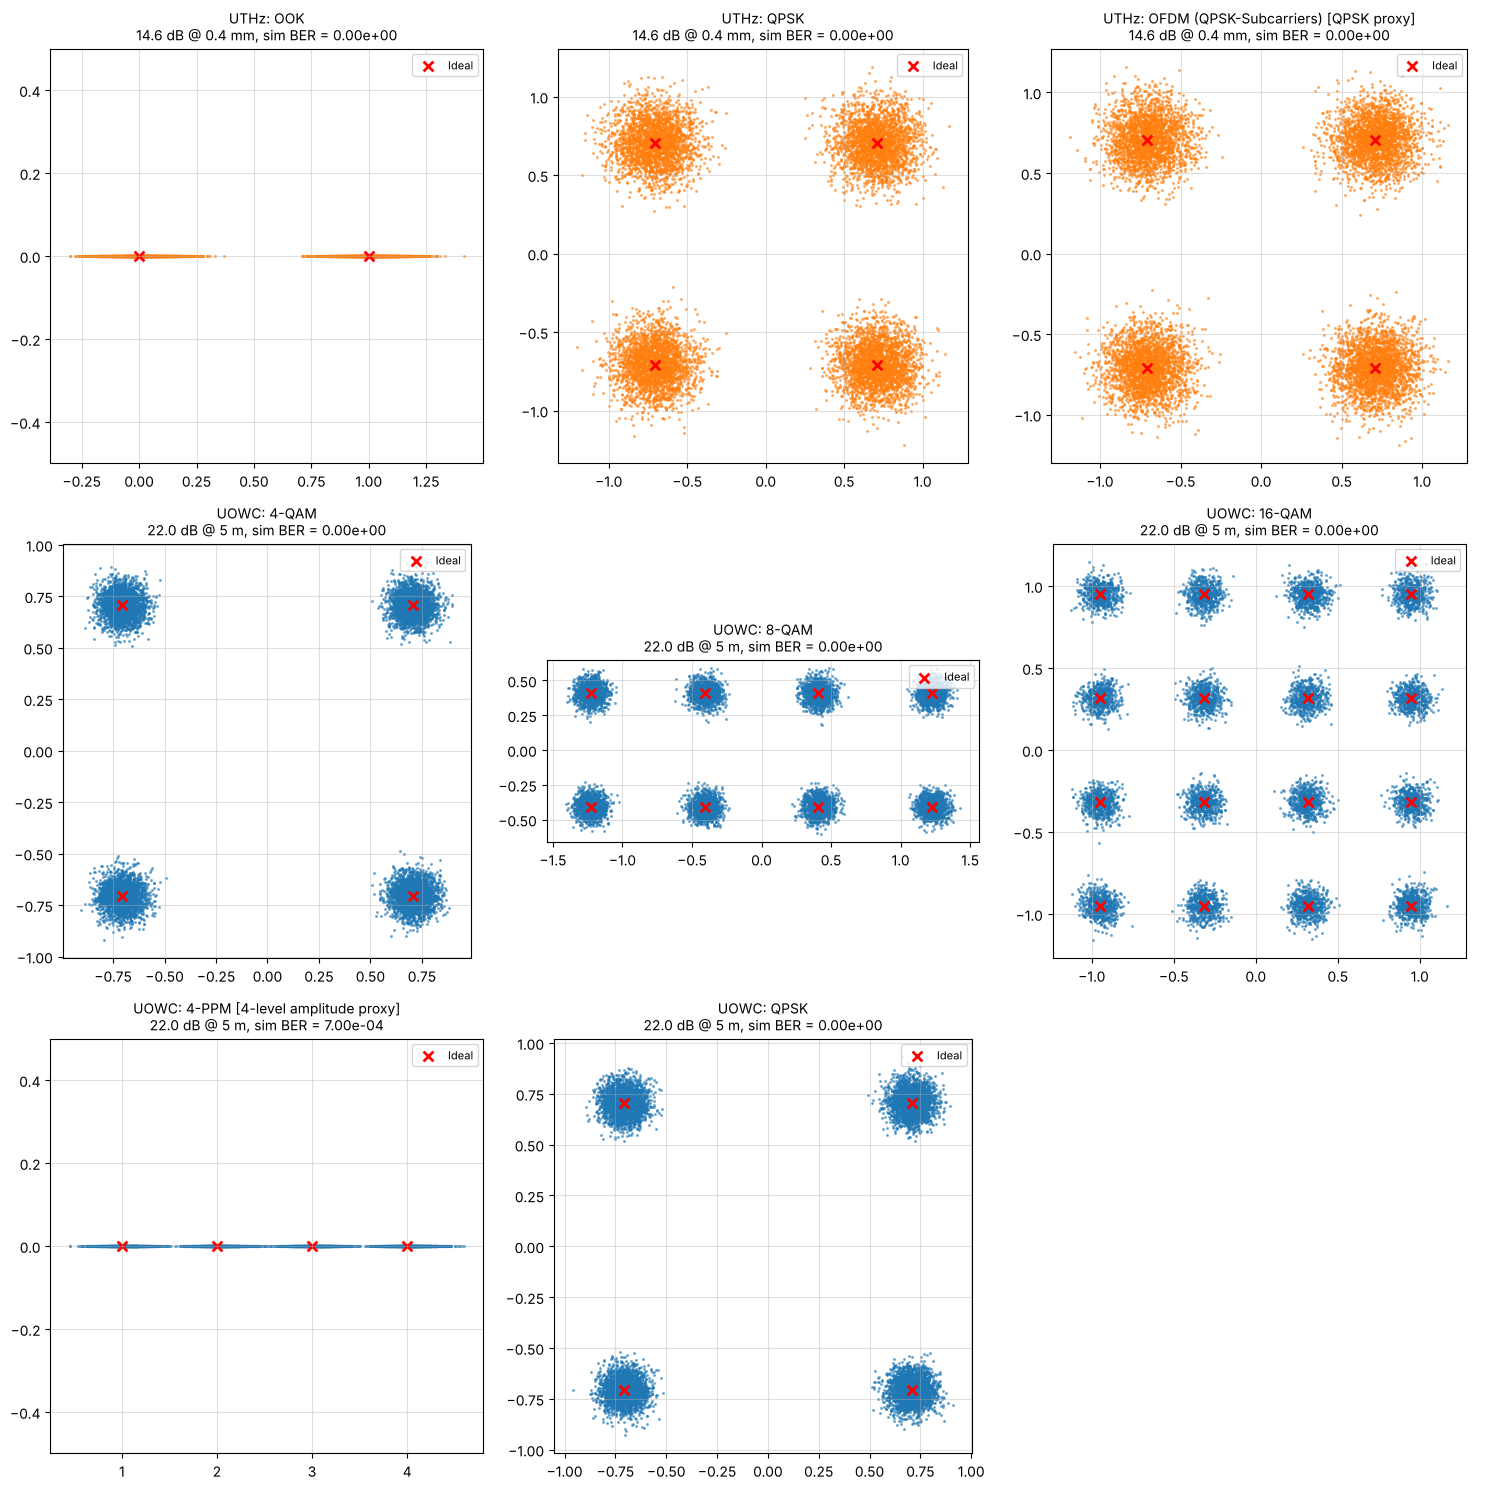

In [8]:
demo_results = {}      # (domain, scheme name) -> simulation result at the demo operating point
for link, cfg in iter_schemes():
    snr_db = float(link_budget(link, link.d_demo)["snr_db"])
    demo_results[(link.name, cfg["name"])] = simulate_link(cfg, snr_db)

items = list(iter_schemes())
ncols = 3
nrows = int(np.ceil(len(items) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 5 * nrows))
axes = np.atleast_2d(axes)

for ax, (link, cfg) in zip(axes.ravel(), items):
    res = demo_results[(link.name, cfg["name"])]
    ax.scatter(res["rx_sym"].real, res["rx_sym"].imag, s=1.5, alpha=0.5, color=link.color)
    ax.scatter(cfg["points"].real, cfg["points"].imag, color="red", marker="x", s=50, linewidths=2, label="Ideal")
    tag = f" [{cfg['note']}]" if cfg["note"] else ""
    ax.set_title(f"{link.name}: {cfg['name']}{tag}\n{res['snr_db']:.1f} dB @ {link.fmt(link.d_demo)}, sim BER = {res['ber']:.2e}", fontsize=10)
    if cfg["is_one_dim"]:
        ax.set_ylim(-0.5, 0.5)
    else:
        ax.set_aspect("equal", "box")
    ax.legend(loc="upper right", fontsize=8)
for ax in axes.ravel()[len(items):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

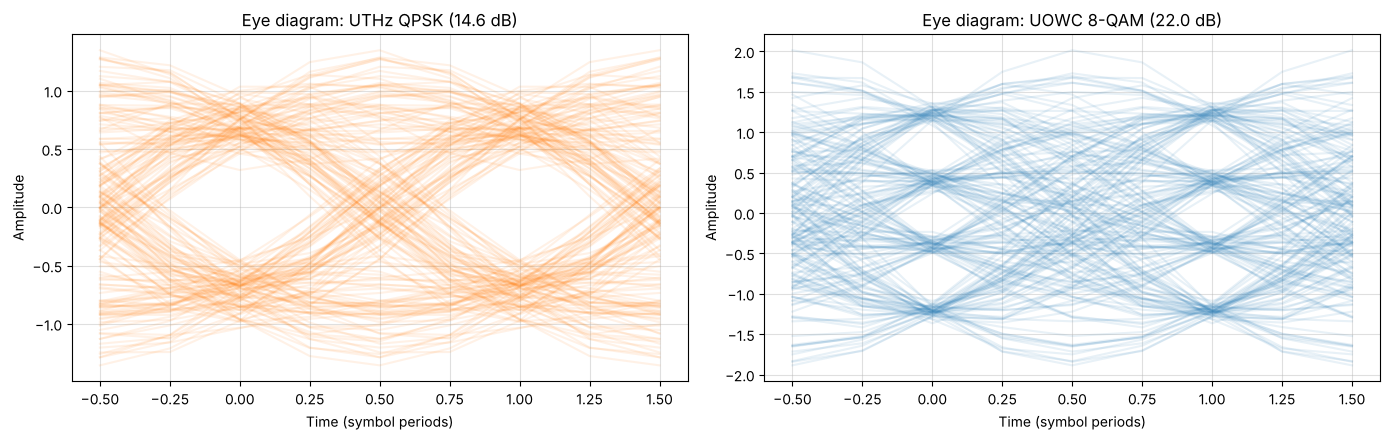

In [9]:
# Eye diagrams (I-channel, matched-filter output) for the featured scheme of each domain
n_traces, span = 200, 2 * sps
starts = DELAY - sps // 2 + sps * np.arange(5, 5 + n_traces)[:, None] + np.arange(span + 1)[None, :]
t = np.arange(span + 1) / sps - (sps // 2) / sps      # symbol periods; decision instants at t = 0 and 1

fig, axes = plt.subplots(1, len(EYE_FOCUS), figsize=(7 * len(EYE_FOCUS), 4.5))
for ax, (domain, scheme_key) in zip(np.atleast_1d(axes), EYE_FOCUS.items()):
    link, cfg = LINKS[domain], LINKS[domain].schemes[scheme_key]
    res = demo_results[(domain, cfg["name"])]
    ax.plot(t, np.real(res["rx_mf"][starts]).T, color=link.color, alpha=0.1)
    ax.set(xlabel="Time (symbol periods)", ylabel="Amplitude",
           title=f"Eye diagram: {domain} {cfg['name']} ({res['snr_db']:.1f} dB)")
plt.tight_layout()
plt.show()

## 9. Simulation vs theory validation
The Monte-Carlo engine (§4) is swept over Eb/N0 for every scheme with a faithful simulation model and overlaid on the theoretical curves from the registry (§2).
Points with zero observed errors cannot be shown on a log axis and are omitted.

**Observation (as configured):** OOK, QPSK and 4-QAM simulations land on their theory curves, which confirms the pulse-shaping / matched-filter / decoder chain.
The 8-QAM and 16-QAM *theory* curves in §2 sit below the Gray-coded simulation (roughly 1.5–3 dB optimistic).
For 16-QAM the textbook approximation is `0.375·erfc(√(0.4·Eb/N0))`, whereas §2 uses `0.8` inside the square root. Update the registry entries if you want the sweeps in §6 to inherit the corrected curves.

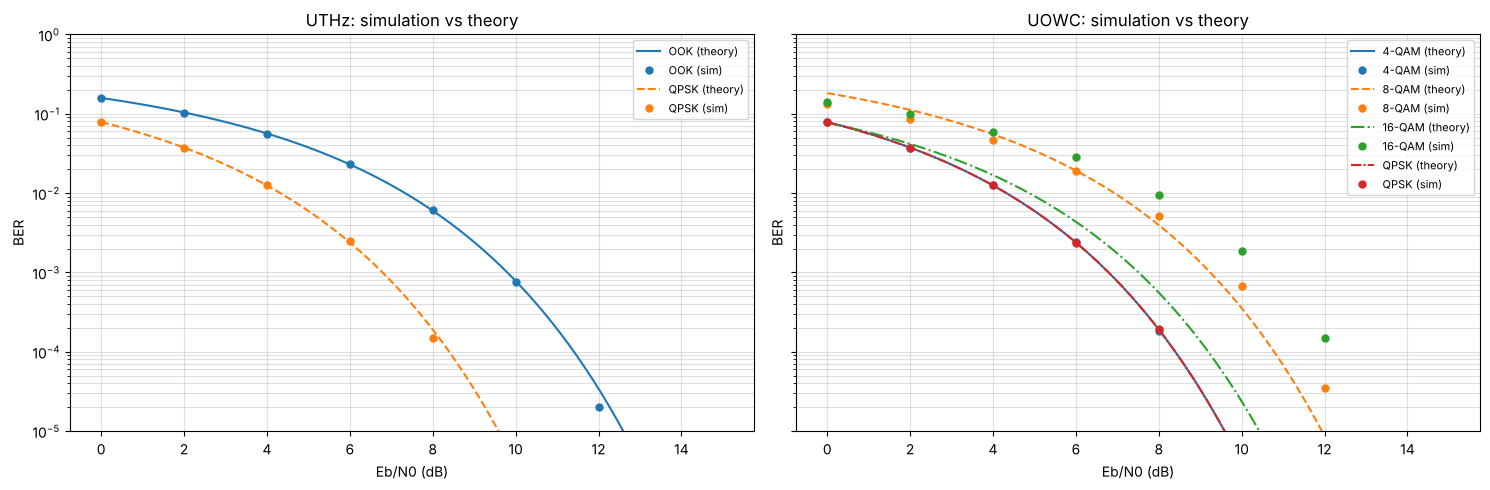

In [10]:
validation_rows = []
fig, axes = plt.subplots(1, len(LINKS), figsize=(7.5 * len(LINKS), 5), sharey=True)
for ax, link in zip(np.atleast_1d(axes), LINKS.values()):
    ebn0_fine_db = np.linspace(0, 15, 150)
    for cfg, style in zip(link.schemes.values(), LINE_STYLES):
        if not cfg["sim_valid"]:
            continue
        k = cfg["bits_per_symbol"]
        line, = ax.plot(ebn0_fine_db, cfg["ber_func"](10 ** (ebn0_fine_db / 10)), ls=style, lw=1.5,
                        label=f"{cfg['name']} (theory)")
        sim = []
        for eb in ebn0_validation_db:
            res = simulate_link(cfg, eb + 10 * np.log10(k), n_symbols=num_symbols_ber)
            sim.append(res["ber"])
            validation_rows.append({"Domain": link.name, "Modulation": cfg["name"], "Eb/N0 (dB)": eb,
                                    "Theory BER": float(cfg["ber_func"](10 ** (eb / 10))), "Simulated BER": res["ber"]})
        sim = np.array(sim, dtype=float)
        sim[sim == 0] = np.nan
        ax.plot(ebn0_validation_db, sim, "o", color=line.get_color(), ms=5, label=f"{cfg['name']} (sim)")
    ax.set(yscale="log", ylim=(1e-5, 1), xlabel="Eb/N0 (dB)", ylabel="BER", title=f"{link.name}: simulation vs theory")
    ax.grid(True, which="both")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

df_validation = pd.DataFrame(validation_rows)

## 10. Consolidated summary
One row per scheme, combining the energy profile (§5), the link budget (§3), theoretical BER at the reference and demo distances (§2–3),
and the simulated BER at the demo distance (§8). `NaN` simulated BER marks proxy schemes (OFDM, 4-PPM) whose simulation is not a faithful model.

In [11]:
summary_rows = []
for (link, cfg), energy_row in zip(iter_schemes(), df_energy.to_dict("records")):
    k = cfg["bits_per_symbol"]
    b_ref, b_demo = link_budget(link, link.d_ref), link_budget(link, link.d_demo)
    sim = demo_results[(link.name, cfg["name"])]["ber"] if cfg["sim_valid"] else np.nan
    summary_rows.append({
        **energy_row,
        "SNR @ ref (dB)": b_ref["snr_db"],
        "Theory BER @ ref": float(cfg["ber_func"](b_ref["snr"] / k)),
        "SNR @ demo (dB)": b_demo["snr_db"],
        "Theory BER @ demo": float(cfg["ber_func"](b_demo["snr"] / k)),
        "Sim BER @ demo": sim,
    })

df_summary = pd.DataFrame(summary_rows)
with pd.option_context("display.float_format", "{:.3g}".format, "display.width", 200):
    display(df_summary)

,Domain,Modulation,Bits/Symbol,Data Rate (Gbps),Duration (ms),Energy Spent (J),SNR @ ref (dB),Theory BER @ ref,SNR @ demo (dB),Theory BER @ demo,Sim BER @ demo
0,UTHz,OOK,1,1,67.1,6.71,42.7,0,14.6,3.83e-08,0
1,UTHz,QPSK,2,2,33.6,3.36,42.7,0,14.6,3.83e-08,0
2,UTHz,OFDM (QPSK-Subcarriers),2,2,33.6,3.36,42.7,0,14.6,3.61e-07,NaN
3,UOWC,4-QAM,2,2,33.6,3.36,22,9.81e-37,22,9.81e-37,0
4,UOWC,8-QAM,3,3,22.4,2.24,22,1.04e-15,22,1.04e-15,0
5,UOWC,16-QAM,4,4,16.8,1.68,22,5.83e-16,22,5.83e-16,0
6,UOWC,4-PPM,2,2,33.6,3.36,22,2.47e-19,22,2.47e-19,NaN
7,UOWC,QPSK,2,2,33.6,3.36,22,9.81e-37,22,9.81e-37,0
